# BGC-Argo POC flux distribution: model (step 3)

| Step | Content | Status |
|---|---|---|
| 0–2 | Source data, raw distributions, data cleaning (`step0-2_data_cleaning.ipynb`) | Done |
| 3 | Fit the model | Done |

## Step 3: Fit the model

**Aim:** Fit one log-normal model per depth to the cleaned `F_5_12`, and for each depth show the parameters, the fit quality and the figures.

The model for one depth, fitted separately at each depth:

```
ln F ~ Normal(mu, sigma)
mu       = b0 + b1 T + b2 C + b3 T C
ln sigma = g0 + g1 T + g2 C + g3 T C
T = ln(SST + 2), C = ln(Chl-a), both standardized within the depth
```

Priors: b ~ Normal(0, 5), g ~ Normal(0, 2). Sampler: NUTS, 4 chains, 1000 warm-up and 1000 sampling iterations.

In [1]:
import logging
import warnings
import cmdstanpy
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from cmcrameri import cm
from pathlib import Path
from scipy.stats import ks_2samp, pearsonr

cmdstanpy.utils.get_logger().setLevel(logging.ERROR)   # hide sampler progress
warnings.filterwarnings("ignore", message=".*matmul.*")   # spurious on macOS; results are checked to be finite below

PROJ = Path(".")

model = cmdstanpy.CmdStanModel(stan_file="model/perdepth_lognormal_v3_1103.stan")
clean = pd.read_csv(PROJ / "cleaned_data.csv")
TERMS = ["intercept", "SST", "Chl-a", "SST x Chl-a"]
PCT = [1, 5, 25, 50, 75, 95, 99, 99.9]


def fit_depth(depth):
    """Fit one depth and return the predictors, ln F and the posterior draws."""
    g = clean[clean["depth"] == depth]
    t, c = np.log(g["sst_day"].values + 2), np.log(g["chl_day"].values)
    t, c = (t - t.mean()) / t.std(), (c - c.mean()) / c.std()
    x = np.column_stack([np.ones(len(g)), t, c, t * c])
    y = np.log(g["F_5_12"].values)
    fit = model.sample(data=dict(N=len(y), p=4, y=y, x=x), chains=4, parallel_chains=4, seed=depth,
                       iter_warmup=1000, iter_sampling=1000, adapt_delta=0.9, show_progress=False)
    beta, gamma = fit.stan_variable("beta"), fit.stan_variable("gamma")
    np.savez(PROJ / f"fits/draws_{depth}m.npz", beta=beta, gamma=gamma)
    return x, y, fit, beta, gamma


def show_parameters(fit):
    s = fit.summary()
    s = s[s.index.str.startswith(("beta", "gamma"))][["Mean", "StdDev", "R_hat", "ESS_bulk", "ESS_tail"]]
    s.index = [f"mu: {t}" for t in TERMS] + [f"ln sigma: {t}" for t in TERMS]
    display(s.round(3))


def show_fit_quality(fit, y, mu, sigma, y_model):
    display(pd.Series({
        "n": len(y),
        "divergent transitions": int(fit.method_variables()["divergent__"].sum()),
        "sigma, median": np.median(sigma),
        "K-S with sigma": ks_2samp(y, y_model).statistic,
        "K-S, sigma = 0": ks_2samp(y, mu).statistic,
        "r with sigma": pearsonr(y, y_model)[0],
        "r, sigma = 0": pearsonr(y, mu)[0],
    }).round(3).to_frame("value"))


def percentile_ratio(x, y, beta, gamma, rng):
    """Model / observed flux at each percentile, averaged over 200 posterior draws."""
    draws = rng.choice(len(beta), 200, replace=False)
    sims = [x @ beta[i] + np.exp(x @ gamma[i]) * rng.standard_normal(len(y)) for i in draws]
    model_pct = np.exp(np.percentile(sims, PCT, axis=1)).mean(axis=1)
    obs_pct = np.exp(np.percentile(y, PCT))
    ratios = pd.DataFrame({"observed": obs_pct, "model": model_pct, "model / observed": model_pct / obs_pct},
                          index=[f"P{p}" for p in PCT])
    ratios.loc["mean"] = [np.exp(y).mean(), np.mean([np.exp(s).mean() for s in sims]),
                          np.mean([np.exp(s).mean() for s in sims]) / np.exp(y).mean()]
    display(ratios.round(3))
    return obs_pct, model_pct


def plot_fit(depth, y, mu, y_model, obs_pct, model_pct):
    fig, ax = plt.subplots(1, 4, figsize=(17, 3.9), constrained_layout=True)
    bins = np.arange(np.floor(y.min()), np.ceil(y.max()) + .2, .2)
    for a, gen, color, label in ((ax[0], y_model, "#e99871", "Model with σ"), (ax[1], mu, "#416c99", "Model, σ = 0")):
        a.hist(y, bins=bins, color="black", alpha=.5, label="Observed")
        a.hist(gen, bins=bins, color=color, alpha=.6, label=label)
        a.set(xlabel="ln F (mmol C m$^{-2}$ d$^{-1}$)", ylabel="Count", xlim=np.percentile(y, [.001, 99.999]))
        a.legend(frameon=False)
    ax[0].set_title(f"{depth} m", loc="left", fontweight="bold")

    lim = (y.min(), y.max())
    ax[2].hexbin(y, mu, cmap=cm.lipari_r, mincnt=1, gridsize=80, extent=(*lim, *lim))
    ax[2].axline((0, 0), (1, 1), color="black", ls="--", lw=1)
    ax[2].set(xlabel="Observed ln F", ylabel="Model ln F, σ = 0", xlim=lim, ylim=lim)

    ax[3].plot(obs_pct, model_pct, "o-", color="#e99871", label="Percentiles P1 to P99.9")
    span = np.array([obs_pct.min() * .7, obs_pct.max() * 1.4])
    ax[3].plot(span, span, color="black", lw=1, label="1:1")
    ax[3].plot(span, span * 1.3, color="gray", ls=":", label="±30%")
    ax[3].plot(span, span * .7, color="gray", ls=":")
    ax[3].set(xscale="log", yscale="log", xlim=span, ylim=span, xlabel="Observed F", ylabel="Model F")
    ax[3].legend(frameon=False, fontsize=8)
    for a in ax:
        a.spines[["top", "right"]].set_visible(False)
    fig.savefig(PROJ / f"figures/step3_fit_{depth}m.png", dpi=200)
    plt.show()


def fit_and_show(depth):
    x, y, fit, beta, gamma = fit_depth(depth)
    mu, sigma = x @ beta.mean(axis=0), np.exp(x @ gamma.mean(axis=0))
    assert np.isfinite(mu).all() and np.isfinite(sigma).all()
    rng = np.random.default_rng(depth)
    y_model = mu + sigma * rng.standard_normal(len(y))
    show_parameters(fit)
    show_fit_quality(fit, y, mu, sigma, y_model)
    obs_pct, model_pct = percentile_ratio(x, y, beta, gamma, rng)
    plot_fit(depth, y, mu, y_model, obs_pct, model_pct)

/Users/yucandong/Library/Python/3.10/lib/python/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 100 m

,Mean,StdDev,R_hat,ESS_bulk,ESS_tail
mu: intercept,2.197,0.002,1.001,4533.85,3149.43
mu: SST,0.024,0.002,1.001,3638.99,2822.03
mu: Chl-a,0.017,0.002,1.001,3799.72,3192.32
mu: SST x Chl-a,-0.032,0.002,1.002,3266.38,3222.24
ln sigma: intercept,-0.809,0.003,1.002,3705.28,2593.77
ln sigma: SST,-0.138,0.003,1.001,3315.71,2892.25
ln sigma: Chl-a,0.152,0.003,1.001,3350.31,2945.59
ln sigma: SST x Chl-a,0.051,0.003,1.000,3472.89,3003.03


,value
n,75276.000
divergent transitions,0.000
"sigma, median",0.436
K-S with sigma,0.048
"K-S, sigma = 0",0.426
r with sigma,0.003
"r, sigma = 0",0.094


,observed,model,model / observed
P1,3.466,2.863,0.826
P5,4.500,4.258,0.946
P25,6.901,6.823,0.989
P50,8.890,9.136,1.028
P75,11.502,12.204,1.061
P95,20.149,19.392,0.962
P99,36.919,28.697,0.777
P99.9,98.555,48.337,0.490
mean,10.401,10.172,0.978


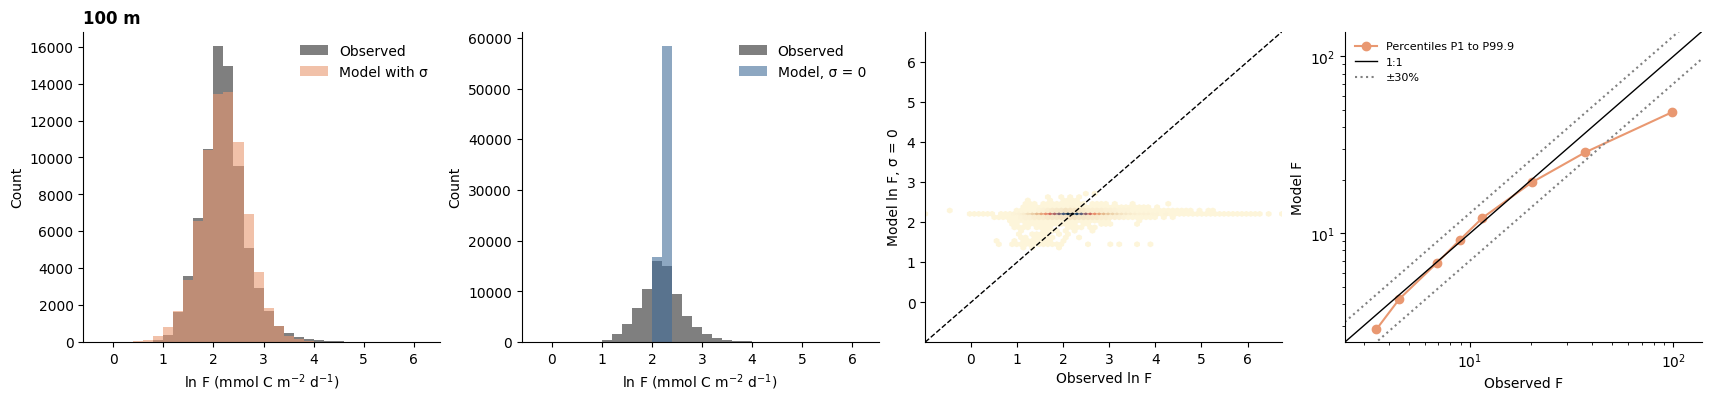

In [2]:
fit_and_show(100)

### 200 m

,Mean,StdDev,R_hat,ESS_bulk,ESS_tail
mu: intercept,1.412,0.002,0.999,5900.35,3101.71
mu: SST,0.040,0.002,1.001,5349.65,3354.89
mu: Chl-a,0.110,0.002,1.000,4823.69,3327.12
mu: SST x Chl-a,-0.009,0.002,1.003,5099.44,3717.93
ln sigma: intercept,-0.955,0.003,1.001,2717.97,2340.88
ln sigma: SST,-0.025,0.003,1.001,2967.94,2879.60
ln sigma: Chl-a,0.116,0.003,1.000,3025.39,2645.02
ln sigma: SST x Chl-a,0.024,0.003,1.001,2858.85,2923.48


,value
n,75062.000
divergent transitions,0.000
"sigma, median",0.386
K-S with sigma,0.053
"K-S, sigma = 0",0.300
r with sigma,0.071
"r, sigma = 0",0.275


,observed,model,model / observed
P1,1.780,1.665,0.935
P5,2.349,2.174,0.925
P25,3.231,3.143,0.973
P50,3.993,4.075,1.020
P75,4.996,5.332,1.067
P95,8.072,8.076,1.000
P99,14.248,11.136,0.782
P99.9,45.586,16.695,0.366
mean,4.584,4.470,0.975


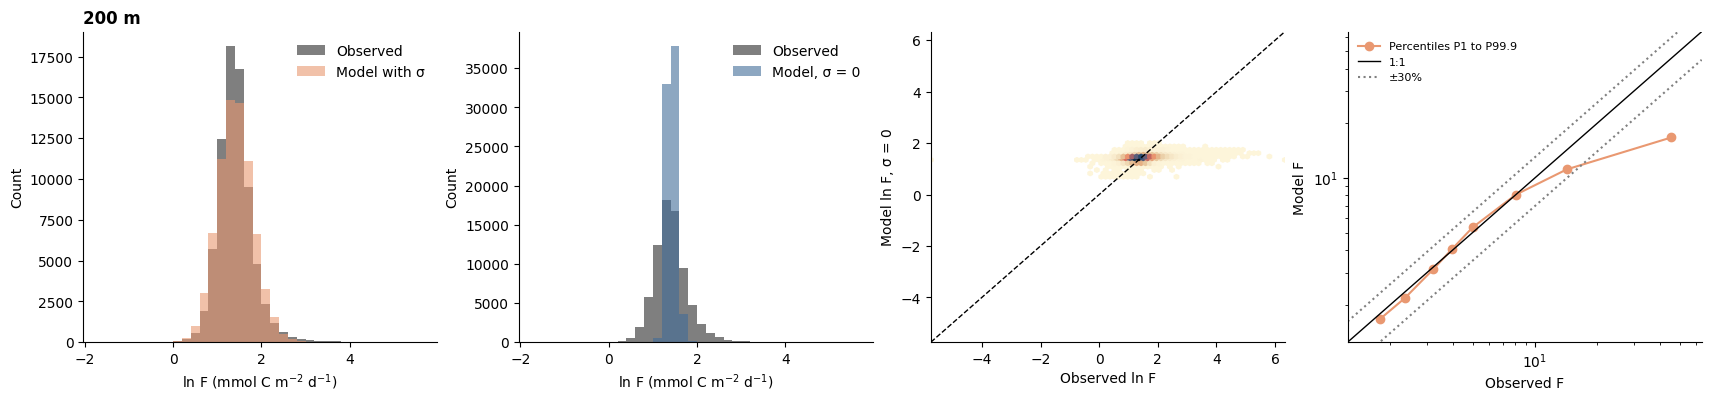

In [3]:
fit_and_show(200)

### 500 m

,Mean,StdDev,R_hat,ESS_bulk,ESS_tail
mu: intercept,0.626,0.002,1.001,5213.43,3345.15
mu: SST,0.063,0.002,1.001,4786.16,3320.92
mu: Chl-a,0.133,0.002,1.000,4892.38,3162.85
mu: SST x Chl-a,0.037,0.002,1.000,3988.37,3107.90
ln sigma: intercept,-0.958,0.003,1.001,2819.15,3183.38
ln sigma: SST,-0.014,0.003,1.002,3182.35,2865.33
ln sigma: Chl-a,0.077,0.003,1.000,2739.79,2361.56
ln sigma: SST x Chl-a,0.026,0.003,1.001,2727.77,2490.92


,value
n,73614.000
divergent transitions,0.000
"sigma, median",0.385
K-S with sigma,0.070
"K-S, sigma = 0",0.223
r with sigma,0.099
"r, sigma = 0",0.307


,observed,model,model / observed
P1,0.742,0.742,1.001
P5,1.068,0.965,0.903
P25,1.467,1.402,0.955
P50,1.790,1.829,1.021
P75,2.210,2.405,1.088
P95,3.564,3.629,1.018
P99,6.949,4.937,0.711
P99.9,23.251,7.159,0.308
mean,2.048,2.004,0.979


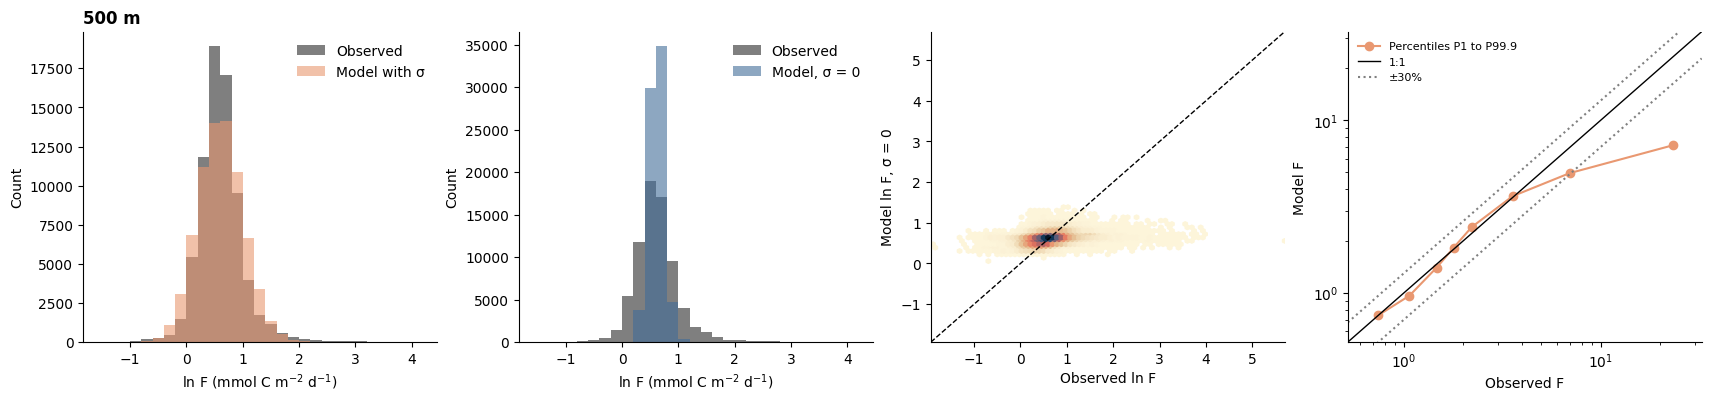

In [4]:
fit_and_show(500)

### 900 m

,Mean,StdDev,R_hat,ESS_bulk,ESS_tail
mu: intercept,0.332,0.002,1.001,5846.49,3001.51
mu: SST,0.044,0.002,1.000,5587.16,3249.77
mu: Chl-a,0.139,0.002,1.000,5167.30,3109.85
mu: SST x Chl-a,0.027,0.002,1.000,5340.98,3499.53
ln sigma: intercept,-0.899,0.003,1.000,3791.83,3215.09
ln sigma: SST,-0.005,0.003,1.002,3269.38,3066.24
ln sigma: Chl-a,0.037,0.003,1.002,3298.87,2844.92
ln sigma: SST x Chl-a,0.010,0.002,1.000,4373.42,3118.34


,value
n,72170.000
divergent transitions,0.000
"sigma, median",0.408
K-S with sigma,0.075
"K-S, sigma = 0",0.221
r with sigma,0.092
"r, sigma = 0",0.299


,observed,model,model / observed
P1,0.497,0.521,1.049
P5,0.786,0.689,0.877
P25,1.094,1.032,0.944
P50,1.348,1.372,1.018
P75,1.667,1.832,1.099
P95,2.708,2.803,1.035
P99,5.240,3.814,0.728
P99.9,19.345,5.444,0.281
mean,1.561,1.512,0.969


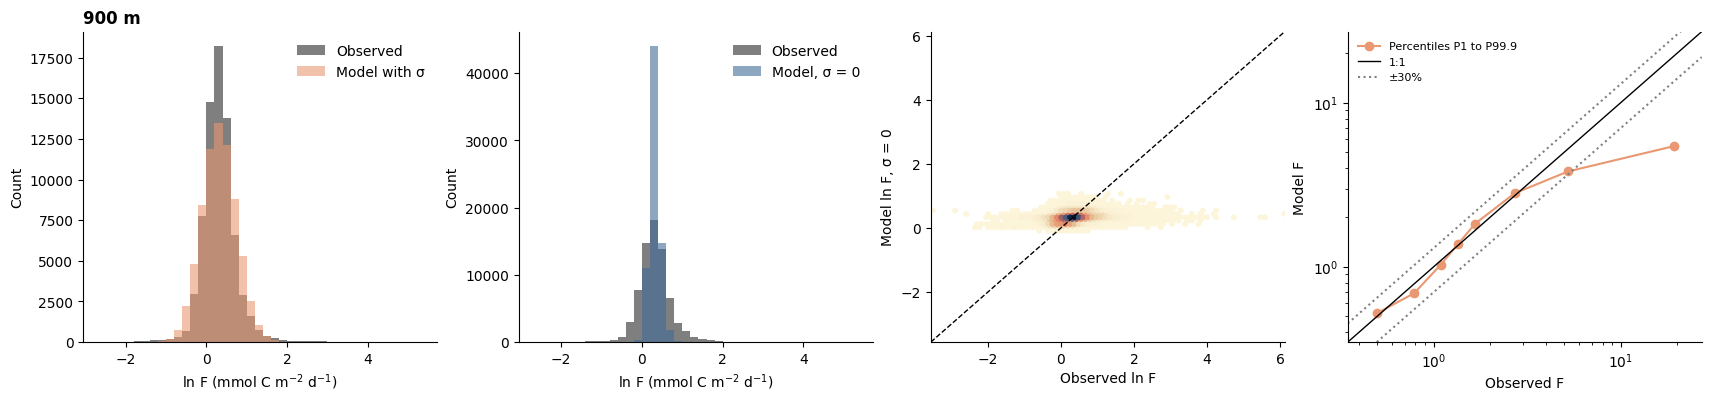

In [5]:
fit_and_show(900)

### Distribution against individual values

In [2]:
from scipy.stats import kstest

# Distribution against individual values, judged with the same +-30% range
def within_30(model, observed):
    return np.mean(np.abs(np.exp(model - observed) - 1) <= .3)

rows = []
for depth, g in clean.groupby("depth"):
    t, c = np.log(g["sst_day"].values + 2), np.log(g["chl_day"].values)
    t, c = (t - t.mean()) / t.std(), (c - c.mean()) / c.std()
    x = np.column_stack([np.ones(len(g)), t, c, t * c])
    y = np.log(g["F_5_12"].values)
    d = np.load(PROJ / f"fits/draws_{depth}m.npz")
    mu, sigma = x @ d["beta"].mean(axis=0), np.exp(x @ d["gamma"].mean(axis=0))
    y_model = mu + sigma * np.random.default_rng(depth).standard_normal(len(y))
    pct = [1, 5, 25, 50, 75, 95]
    rows.append({
        "depth": depth,
        "K-S with sigma": ks_2samp(y, y_model).statistic,
        "K-S, sigma = 0": ks_2samp(y, mu).statistic,
        "K-S, no predictors": kstest(y, "norm", args=(y.mean(), y.std())).statistic,
        "percentiles P1-P95 within 30%": within_30(np.percentile(y_model, pct), np.percentile(y, pct)),
        "values within 30%: model": within_30(mu, y),
        "values within 30%: depth median only": within_30(np.median(y), y),
        "typical error factor: model": np.exp(np.median(np.abs(y - mu))),
        "typical error factor: depth median only": np.exp(np.median(np.abs(y - np.median(y)))),
        "r2": pearsonr(y, mu)[0] ** 2,
    })
quality = pd.DataFrame(rows).set_index("depth").T
quality.to_csv(PROJ / "step3_distribution_vs_values.csv")
quality.round(3)

depth,100,200,500,900
K-S with sigma,0.048,0.053,0.070,0.075
"K-S, sigma = 0",0.426,0.300,0.223,0.221
"K-S, no predictors",0.057,0.068,0.076,0.079
percentiles P1-P95 within 30%,1.000,1.000,1.000,1.000
values within 30%: model,0.564,0.647,0.687,0.676
values within 30%: depth median only,0.570,0.638,0.666,0.650
typical error factor: model,1.292,1.236,1.209,1.216
typical error factor: depth median only,1.291,1.243,1.227,1.234
r2,0.009,0.076,0.094,0.089


**Conclusion: the model reproduces the distribution, up to about P95, but it has almost no skill for individual values.**

| Depth | 100 m | 200 m | 500 m | 900 m |
|---|---:|---:|---:|---:|
| **Distribution:** K-S with σ | 0.048 | 0.053 | 0.070 | 0.075 |
| K-S with σ = 0 | 0.426 | 0.300 | 0.223 | 0.221 |
| K-S with no predictors (one mean and SD per depth) | 0.057 | 0.068 | 0.076 | 0.079 |
| Percentiles P1–P95 within ±30% | 6 of 6 | 6 of 6 | 6 of 6 | 6 of 6 |
| P99 model / observed | 0.78 | 0.78 | 0.71 | 0.73 |
| P99.9 model / observed | 0.49 | 0.37 | 0.31 | 0.28 |
| **Individual values:** r² | 0.01 | 0.08 | 0.09 | 0.09 |
| Within ±30%: model | 56.4% | 64.7% | 68.7% | 67.6% |
| Within ±30%: depth median only | 57.0% | 63.8% | 66.6% | 65.0% |

**Why the distribution counts as good:**
- K-S is the largest gap between the observed and modelled cumulative distributions, so 0.048 means the two differ by at most 4.8% of the profiles.
- This gap is 3 to 9 times smaller than with σ = 0, and at 100 m it is close to the 0.044 of Edwards et al. (2026).
- Most of this agreement exists because the flux is close to log-normal: one mean and one SD per depth, both taken from the POC data, already give K-S 0.057–0.079. SST and Chl-a improve it by only 0.004–0.015.
- All percentiles from P1 to P95 are within ±30%. Above that the fit fails: P99 is 22–29% low and P99.9 is 51–72% low.

**Why individual values count as poor:**
- SST and Chl-a explain 1–9% of the variance of ln F.
- The fair reference is a prediction with no predictors, a single median for each depth. It places 57–67% of the profiles within ±30%, and the model changes this by −0.6 to +2.6 percentage points. Using the model is therefore almost no better than using one number per depth.
- The 56–69% is not itself a sign of skill. It is high because the flux at a given depth has a narrow distribution.

**How to read the two quantities:**
- **σ** is the width of ln F around the model value. It gives the distribution its spread (K-S 0.05–0.08 against 0.22–0.43 without it), but it is random, so it cannot improve individual values.
- **r** is the profile-by-profile correlation between observed and modelled ln F. Use r with σ = 0 and its square for skill. r with σ is lower only because it adds that random draw.

All fits converged (R-hat ≤ 1.003, ESS above 2,300, no divergent transitions). There is no float effect, so posterior widths are too narrow.